# 03b — Feature Selection (part B) & Baseline Models: Decision Tree and SVM
EC5203 Group 07 — Member 3, part B

Continues `03_feature_selection.ipynb` (part A: correlation screen, mutual information, Logistic Regression, KNN).

This notebook adds:
- Feature selection method 3: **model-based importance** (Decision Tree)
- Feature selection method 4: **RFE**
- Baselines 3 and 4: **Decision Tree** and **SVM** (`src/models_baseline_b.py`)
- The same three configurations as part A: Original / Engineered / Engineered_Selected (MI, k=20)
- A combined table of all four baselines on the **validation** set

The **test set is not used**. It is reserved for the final comparison with Member 4.

In [1]:
from pathlib import Path
import sys, json, platform

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").is_dir():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Project src folder was not found.")
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
print("Project Root:", PROJECT_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import RFE
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             classification_report, ConfusionMatrixDisplay)

from src.preprocessing import prepare_dataset
from src.three_way_split import split_three_ways
from src.pipeline import build_pipeline
from src.models_baseline_b import build_decision_tree_pipeline, build_svm_pipeline

RANDOM_STATE = 42
K_FEATURES = 20            # same k as part A
SVM_TRAIN_LIMIT = 10_000   # RBF SVM is O(n^2); same idea as part A's KNN_TRAIN_LIMIT
RFE_SAMPLE = 20_000        # training rows used for RFE (speed)

TAB_DIR = PROJECT_ROOT / "results" / "tables";  TAB_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = PROJECT_ROOT / "results" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)

Project Root: <project root>


## 1. Load data and the approved 70/15/15 split

In [2]:
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Data Warehouse Multiclass.csv"
X, y = prepare_dataset(DATA_PATH)

X_train, X_val, X_test, y_train, y_val, y_test = split_three_ways(X, y, random_state=RANDOM_STATE)
print("Training:", X_train.shape, "| Validation:", X_val.shape, "| Testing:", X_test.shape)
# Test data must remain untouched during feature and model selection.

=== DATASET PREPARATION ===
Original shape: (280985, 39)
Predictor shape: (280985, 24)
Target shape: (280985,)


Exact duplicates: 2284
Target classes: 8

Class distribution:
sublabel
N           106884
HY           69806
DI_HY        66473
DI           31918
HT            2595
DI_HT         1398
HT_HY         1066
DI_HT_HY       845
Name: count, dtype: int64



=== DUPLICATE HANDLING ===
Original records: 280985
Exact duplicate records removed: 2284
Remaining records: 278701

=== 70/15/15 DATA SPLIT ===
Training: 195091 (70.00%)
Validation: 41805 (15.00%)
Testing: 41805 (15.00%)

=== CLASS DISTRIBUTION (%) ===
            Original  Training  Validation  Testing
__target__                                         
N              37.55     37.55       37.55    37.55
HY             25.04     25.04       25.04    25.04
DI_HY          23.85     23.85       23.85    23.85
DI             11.45     11.45       11.45    11.45
HT              0.93      0.93        0.93     0.93
DI_HT           0.50      0.50        0.50     0.50
HT_HY           0.38      0.38        0.38     0.38
DI_HT_HY        0.30      0.30        0.30     0.30



SUCCESS: No overlapping predictor groups.
SUCCESS: All eight classes represented.
Training: (195091, 24) | Validation: (41805, 24) | Testing: (41805, 24)


## 2. Feature selection method 3 — Decision Tree importance (training data only)

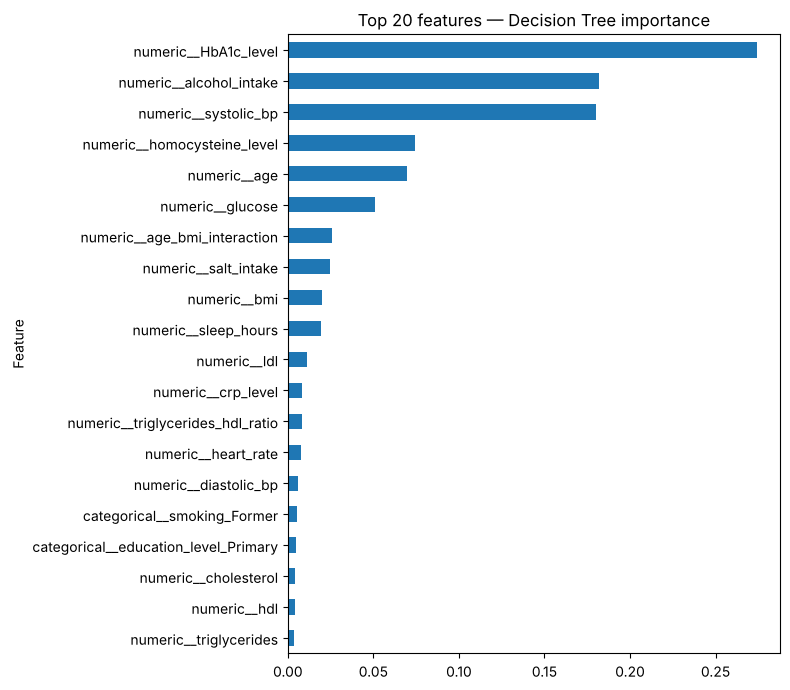

In [3]:
fs_preprocessor = build_pipeline(X_train, use_engineering=True)
X_train_t = fs_preprocessor.fit_transform(X_train, y_train)
feature_names = fs_preprocessor.named_steps["preprocessing"].get_feature_names_out()

importance_tree = DecisionTreeClassifier(max_depth=12, min_samples_leaf=20,
                                         class_weight="balanced", random_state=RANDOM_STATE)
importance_tree.fit(X_train_t, y_train)

tree_importance = (pd.DataFrame({"Feature": feature_names,
                                 "Importance": importance_tree.feature_importances_})
                   .sort_values("Importance", ascending=False).reset_index(drop=True))
tree_importance.to_csv(TAB_DIR / "tree_importance_scores.csv", index=False)

tree_importance.head(20).plot.barh(x="Feature", y="Importance", figsize=(8, 7), legend=False).invert_yaxis()
plt.title("Top 20 features — Decision Tree importance"); plt.tight_layout()
plt.savefig(FIG_DIR / "03b_tree_importance.png", dpi=150); plt.show()

## 3. Feature selection method 4 — RFE (training data only)

In [4]:
idx = np.arange(len(y_train))
if len(idx) > RFE_SAMPLE:
    idx, _ = train_test_split(idx, train_size=RFE_SAMPLE, stratify=y_train, random_state=RANDOM_STATE)

rfe = RFE(DecisionTreeClassifier(max_depth=12, min_samples_leaf=20,
                                 class_weight="balanced", random_state=RANDOM_STATE),
          n_features_to_select=K_FEATURES, step=2)
rfe.fit(X_train_t[idx], y_train.iloc[idx])

rfe_table = (pd.DataFrame({"Feature": feature_names, "RFE_Rank": rfe.ranking_,
                           "Selected": rfe.support_})
             .sort_values("RFE_Rank").reset_index(drop=True))
rfe_table.to_csv(TAB_DIR / "rfe_ranking.csv", index=False)
rfe_table.head(K_FEATURES)

,Feature,RFE_Rank,Selected
0,numeric__age,1,True
1,numeric__bmi,1,True
2,numeric__HbA1c_level,1,True
3,numeric__glucose,1,True
4,numeric__cholesterol,1,True
5,numeric__sleep_hours,1,True
6,numeric__triglycerides,1,True
7,numeric__crp_level,1,True
8,numeric__homocysteine_level,1,True
9,numeric__systolic_bp,1,True


## 4. Compare the selection methods (MI from part A vs tree importance vs RFE)

In [5]:
mi_path = TAB_DIR / "mutual_information_scores.csv"   # produced by part A
mi_top = pd.read_csv(mi_path)["Feature"].head(K_FEATURES).tolist() if mi_path.is_file() else []
tree_top = tree_importance["Feature"].head(K_FEATURES).tolist()
rfe_top = rfe_table.loc[rfe_table["Selected"], "Feature"].tolist()

all_feats = sorted(set(mi_top) | set(tree_top) | set(rfe_top))
agreement = pd.DataFrame({
    "Feature": all_feats,
    "Mutual_Information": [f in mi_top for f in all_feats],
    "Tree_Importance": [f in tree_top for f in all_feats],
    "RFE": [f in rfe_top for f in all_feats],
})
agreement["Votes"] = agreement[["Mutual_Information", "Tree_Importance", "RFE"]].sum(axis=1)
agreement = agreement.sort_values(["Votes", "Feature"], ascending=[False, True]).reset_index(drop=True)
agreement.to_csv(TAB_DIR / "feature_selection_agreement.csv", index=False)
print("Note: part A computed MI on the original (non-engineered) features.")
agreement

Note: part A computed MI on the original (non-engineered) features.


,Feature,Mutual_Information,Tree_Importance,RFE,Votes
0,numeric__HbA1c_level,True,True,True,3
1,numeric__age,True,True,True,3
2,numeric__alcohol_intake,True,True,True,3
3,numeric__bmi,True,True,True,3
4,numeric__cholesterol,True,True,True,3
5,numeric__crp_level,True,True,True,3
6,numeric__diastolic_bp,True,True,True,3
7,numeric__glucose,True,True,True,3
8,numeric__hdl,True,True,True,3
9,numeric__heart_rate,True,True,True,3


## 5. Evaluation function (same as part A)

In [6]:
def evaluate_model(model, X_train_data, y_train_data, X_validation, y_validation, model_name, configuration):
    model.fit(X_train_data, y_train_data)
    predictions = model.predict(X_validation)
    metrics = {
        "Model": model_name,
        "Configuration": configuration,
        "Accuracy": accuracy_score(y_validation, predictions),
        "Macro_F1": f1_score(y_validation, predictions, average="macro", zero_division=0),
        "Weighted_F1": f1_score(y_validation, predictions, average="weighted", zero_division=0),
        "Balanced_Accuracy": balanced_accuracy_score(y_validation, predictions),
    }
    report = classification_report(y_validation, predictions, output_dict=True, zero_division=0)
    return metrics, pd.DataFrame(report).transpose(), model, predictions

## 6. Training subset for SVM (RBF SVM does not scale to ~195k rows)

In [7]:
if len(X_train) > SVM_TRAIN_LIMIT:
    X_svm_train, _, y_svm_train, _ = train_test_split(
        X_train, y_train, train_size=SVM_TRAIN_LIMIT, random_state=RANDOM_STATE, stratify=y_train)
else:
    X_svm_train, y_svm_train = X_train.copy(), y_train.copy()

print("Decision Tree training rows:", len(X_train))
print("SVM training rows:", len(X_svm_train))
print("Validation rows:", len(X_val))

Decision Tree training rows: 195091
SVM training rows: 10000
Validation rows: 41805


## 7. Run Decision Tree and SVM on the three configurations

In [8]:
experiments, class_reports, predictions_store = [], [], {}

configurations = [
    ("Original", False, False),
    ("Engineered", True, False),
    ("Engineered_Selected", True, True),
]

for configuration, use_engineering, selected in configurations:
    # Decision Tree (full training set)
    dt = build_decision_tree_pipeline(X_train, use_engineering=use_engineering,
                                      selected=selected, k_features=K_FEATURES)
    m, r, dt, p = evaluate_model(dt, X_train, y_train, X_val, y_val, "Decision Tree", configuration)
    experiments.append(m); r["Model"] = "Decision Tree"; r["Configuration"] = configuration
    class_reports.append(r); predictions_store[("Decision Tree", configuration)] = p
    print(f"Decision Tree | {configuration:20s} | Macro F1 = {m['Macro_F1']:.4f}")

    # SVM (stratified subset)
    svm = build_svm_pipeline(X_train, use_engineering=use_engineering,
                             selected=selected, k_features=K_FEATURES)
    m, r, svm, p = evaluate_model(svm, X_svm_train, y_svm_train, X_val, y_val, "SVM (RBF)", configuration)
    experiments.append(m); r["Model"] = "SVM (RBF)"; r["Configuration"] = configuration
    class_reports.append(r); predictions_store[("SVM (RBF)", configuration)] = p
    print(f"SVM (RBF)     | {configuration:20s} | Macro F1 = {m['Macro_F1']:.4f}")

print("All part B baseline experiments completed.")

Decision Tree | Original             | Macro F1 = 0.3687


SVM (RBF)     | Original             | Macro F1 = 0.3605


Decision Tree | Engineered           | Macro F1 = 0.3702


SVM (RBF)     | Engineered           | Macro F1 = 0.3603


Decision Tree | Engineered_Selected  | Macro F1 = 0.3675


SVM (RBF)     | Engineered_Selected  | Macro F1 = 0.3408
All part B baseline experiments completed.


## 8. Save part B results

In [9]:
metrics_b = pd.DataFrame(experiments).sort_values("Macro_F1", ascending=False)
metrics_b.to_csv(TAB_DIR / "baseline_b_validation_metrics.csv", index=False)
pd.concat(class_reports).to_csv(TAB_DIR / "class_wise_validation_metrics_b.csv")
metrics_b

,Model,Configuration,Accuracy,Macro_F1,Weighted_F1,Balanced_Accuracy
2,Decision Tree,Engineered,0.647411,0.370175,0.664221,0.557999
0,Decision Tree,Original,0.644731,0.368744,0.664007,0.555789
4,Decision Tree,Engineered_Selected,0.641454,0.367544,0.659665,0.556527
1,SVM (RBF),Original,0.645832,0.360489,0.667490,0.448588
3,SVM (RBF),Engineered,0.645306,0.360290,0.667243,0.448735
5,SVM (RBF),Engineered_Selected,0.619160,0.340830,0.646031,0.447629


## 9. All four baselines together (part A + part B)

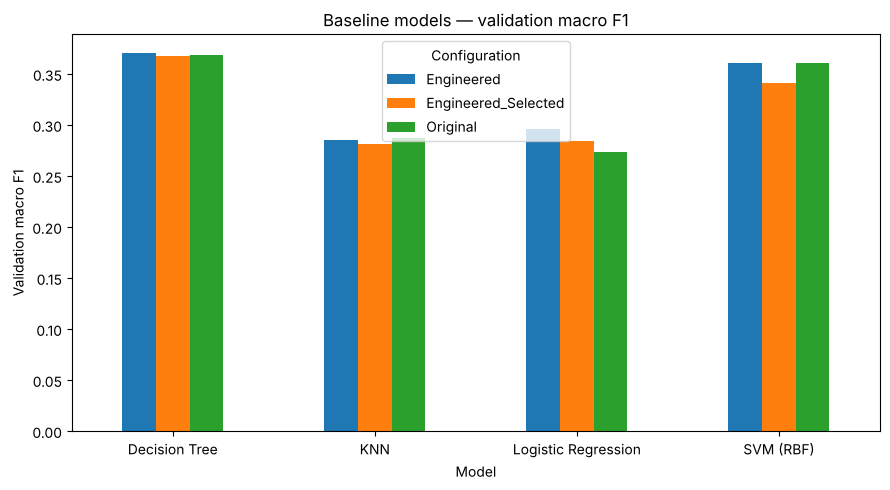

,Model,Configuration,Accuracy,Macro_F1,Weighted_F1,Balanced_Accuracy
0,Decision Tree,Engineered,0.647411,0.370175,0.664221,0.557999
1,Decision Tree,Original,0.644731,0.368744,0.664007,0.555789
2,Decision Tree,Engineered_Selected,0.641454,0.367544,0.659665,0.556527
3,SVM (RBF),Original,0.645832,0.360489,0.667490,0.448588
4,SVM (RBF),Engineered,0.645306,0.360290,0.667243,0.448735
5,SVM (RBF),Engineered_Selected,0.619160,0.340830,0.646031,0.447629
6,Logistic Regression,Engineered,0.489140,0.296151,0.555105,0.475480
7,KNN,Original,0.613859,0.287209,0.601044,0.284667
8,KNN,Engineered,0.605846,0.285457,0.593990,0.281991
9,Logistic Regression,Engineered_Selected,0.468043,0.284018,0.537431,0.443879


In [10]:
a_path = TAB_DIR / "baseline_validation_metrics.csv"   # part A results (LR, KNN)
all_metrics = pd.concat([pd.read_csv(a_path), metrics_b]) if a_path.is_file() else metrics_b.copy()
all_metrics = all_metrics.sort_values("Macro_F1", ascending=False).reset_index(drop=True)
all_metrics.to_csv(TAB_DIR / "all_baseline_validation_metrics.csv", index=False)

pivot = all_metrics.pivot(index="Model", columns="Configuration", values="Macro_F1")
pivot.plot.bar(figsize=(9, 5), rot=0)
plt.ylabel("Validation macro F1"); plt.title("Baseline models — validation macro F1")
plt.tight_layout(); plt.savefig(FIG_DIR / "03b_all_baselines_macro_f1.png", dpi=150); plt.show()
all_metrics

## 10. Best part B model — validation confusion matrix

Best part B: Decision Tree | Engineered | Macro F1 = 0.3702
              precision    recall  f1-score   support

          DI      0.315     0.125     0.179      4786
       DI_HT      0.113     0.459     0.182       209
    DI_HT_HY      0.071     0.595     0.128       126
       DI_HY      0.720     0.812     0.763      9971
          HT      0.065     0.590     0.116       388
       HT_HY      0.060     0.444     0.106       160
          HY      0.718     0.896     0.797     10468
           N      0.950     0.543     0.691     15697

    accuracy                          0.647     41805
   macro avg      0.377     0.558     0.370     41805
weighted avg      0.746     0.647     0.664     41805



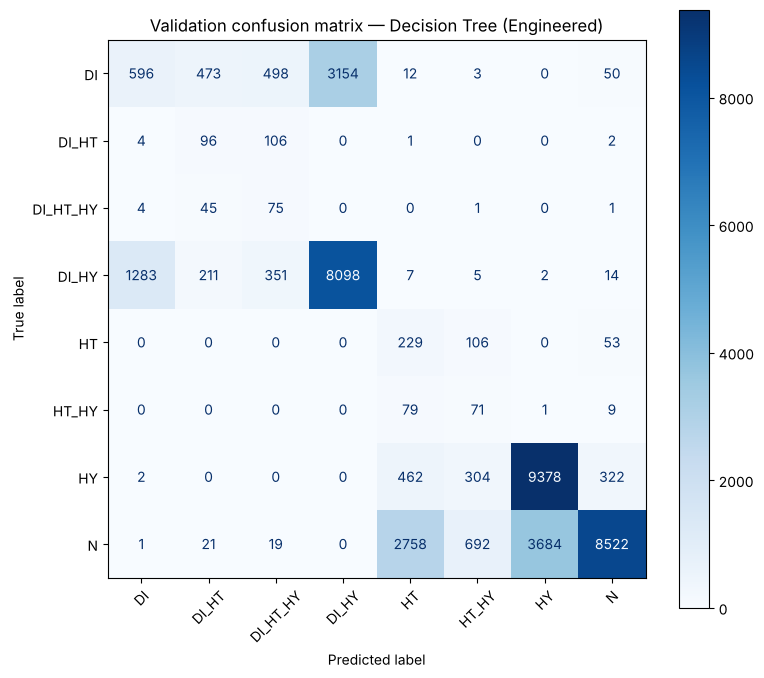

In [11]:
best = metrics_b.iloc[0]
pred = predictions_store[(best["Model"], best["Configuration"])]
print("Best part B:", best["Model"], "|", best["Configuration"], "| Macro F1 =", round(best["Macro_F1"], 4))
print(classification_report(y_val, pred, digits=3, zero_division=0))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_val, pred, ax=ax, xticks_rotation=45, cmap="Blues")
plt.title(f"Validation confusion matrix — {best['Model']} ({best['Configuration']})")
plt.tight_layout(); plt.savefig(FIG_DIR / "03b_best_confusion_matrix.png", dpi=150); plt.show()

## 11. Save settings (reproducibility, handoff to Member 4)

In [12]:
settings = {
    "random_state": RANDOM_STATE, "split": "70/15/15 grouped (src.three_way_split)",
    "k_features": K_FEATURES, "svm_train_limit": SVM_TRAIN_LIMIT, "rfe_sample": RFE_SAMPLE,
    "evaluation": "fit on training data, evaluate on validation; test set unused",
    "decision_tree": str(build_decision_tree_pipeline(X_train).named_steps["classifier"]),
    "svm": str(build_svm_pipeline(X_train).named_steps["classifier"]),
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__},
}
with open(TAB_DIR / "baseline_b_settings.json", "w") as f:
    json.dump(settings, f, indent=2)
settings

{'random_state': 42,
 'split': '70/15/15 grouped (src.three_way_split)',
 'k_features': 20,
 'svm_train_limit': 10000,
 'rfe_sample': 20000,
 'evaluation': 'fit on training data, evaluate on validation; test set unused',
 'decision_tree': "DecisionTreeClassifier(class_weight='balanced', max_depth=12,\n                       min_samples_leaf=20, random_state=42)",
 'svm': "SVC(class_weight='balanced', random_state=42)",
 'versions': {'python': '3.13.18',
  'sklearn': '1.9.1',
  'pandas': '3.0.5',
  'numpy': '2.5.3'}}

## 12. Interpretation (write after running)
- Which features appear in all three selection methods (`Votes = 3`)?
- Did Engineered or Engineered_Selected improve Decision Tree / SVM over Original?
- Which of the four baselines is best on validation macro F1?
- Which classes are hardest (DI_HT_HY, DI_HT, HT_HY)?
- Limitations: SVM trained on a 10k subset, RFE on a 20k subset, class imbalance, unverified units.